In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

data = pd.read_csv("train.csv")
data['date'] = pd.to_datetime(data['date'])

df = data[(data['store'] == 1) & (data['item'] == 1)].copy()
df = df.sort_values('date')

# Lag features
df['lag_1'] = df['sales'].shift(1)
df['lag_7'] = df['sales'].shift(7)
df['lag_30'] = df['sales'].shift(30)

# Rolling features
df['rolling_7'] = df['sales'].shift(1).rolling(7).mean()
df['rolling_30'] = df['sales'].shift(1).rolling(30).mean()

# Calendar features
df['month'] = df['date'].dt.month
df['day_of_week'] = df['date'].dt.dayofweek

df = df.dropna()


In [2]:
split_index = int(len(df) * 0.8)

train = df.iloc[:split_index]
valid = df.iloc[split_index:]

features = ['lag_1','lag_7','lag_30',
            'rolling_7','rolling_30',
            'month','day_of_week']

X_train = train[features]
y_train = train['sales']

X_valid = valid[features]
y_valid = valid['sales']

model = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_valid)


In [3]:
mae = mean_absolute_error(y_valid, predictions)
rmse = np.sqrt(mean_squared_error(y_valid, predictions))

print("Enhanced XGBoost MAE:", mae)
print("Enhanced XGBoost RMSE:", rmse)


Enhanced XGBoost MAE: 4.187130451202393
Enhanced XGBoost RMSE: 5.256731712956441


<Figure size 1000x600 with 0 Axes>

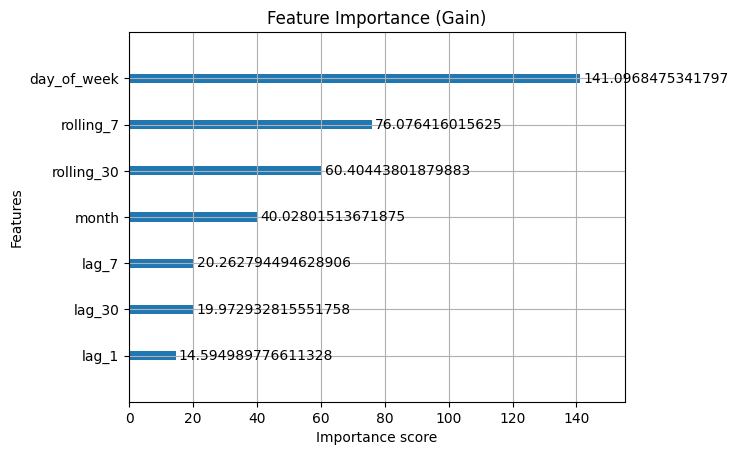

In [4]:
plt.figure(figsize=(10,6))
xgb.plot_importance(model, importance_type='gain')
plt.title("Feature Importance (Gain)")
plt.show()

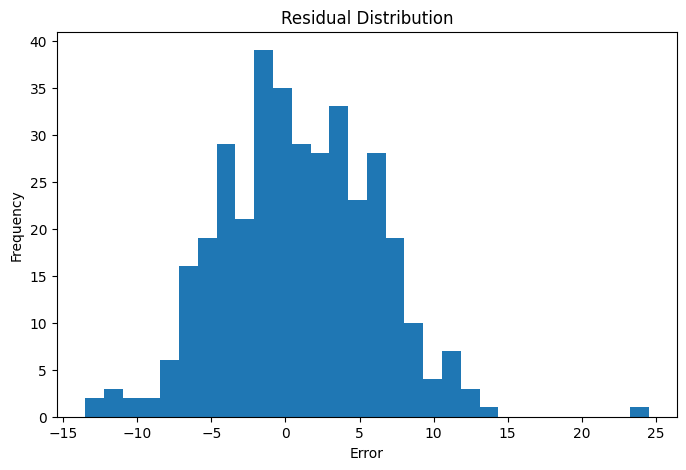

In [5]:
residuals = y_valid - predictions

plt.figure(figsize=(8,5))
plt.hist(residuals, bins=30)
plt.title("Residual Distribution")
plt.xlabel("Error")
plt.ylabel("Frequency")
plt.show()


In [6]:
print("Mean Residual:", residuals.mean())


Mean Residual: 0.9237837606006198


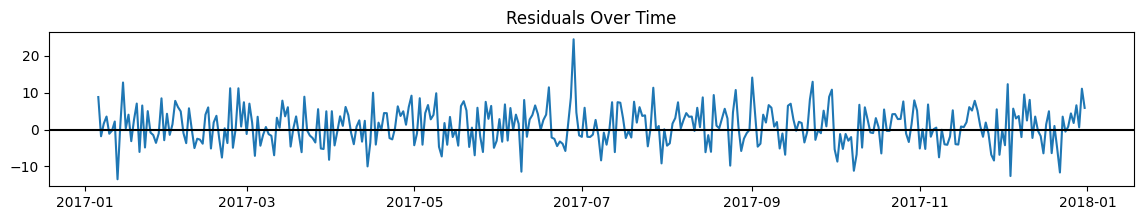

In [12]:
plt.figure(figsize=(14,2))
plt.plot(valid['date'], residuals)
plt.axhline(0, color='black')
plt.title("Residuals Over Time")
plt.show()
